In [ ]:
!pip install pydicom


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 7.5 MB/s eta 0:00:00


In [ ]:
import numpy as np
import pydicom
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt

dicom_file_path = '/content/MR.1.2.246.352.221.48796771702578547143190337873135985819.dcm'

# Чтение DICOM-файла
ds = pydicom.dcmread(dicom_file_path)

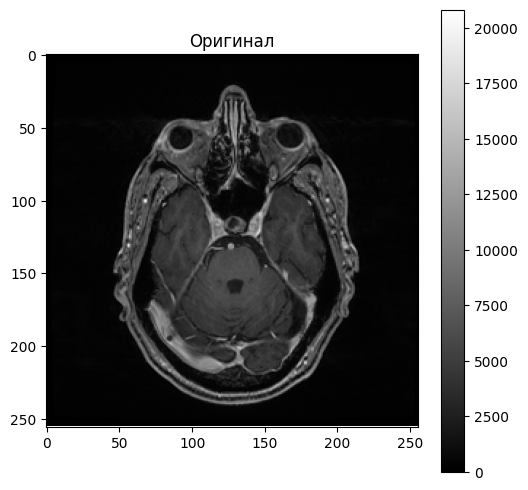

In [ ]:
# Получение массива пикселей
image = ds.pixel_array

# Отображение картинки
plt.figure(figsize=(6, 6))
plt.imshow(image, cmap='gray')
plt.title('Оригинал')
plt.colorbar()
plt.show()

In [ ]:
# Получаем массив пикселей
image = ds.pixel_array

# Функция для растягивания гистограммы (линейная нормировка яркости)
def histogram_stretching(image):
    # Находим минимальное и максимальное значения интенсивности пикселей в текущем изображении
    min_val = np.min(image)
    max_val = np.max(image)

    # Применяем формулу линейного растяжения:
    # 1. Вычитаем min_val, чтобы сместить минимальное значение в 0
    # 2. Делим на (max_val - min_val), чтобы привести диапазон к [0, 1]
    # 3. Умножаем на 255, чтобы расширить диапазон до стандартных [0, 255]
    # 4. Преобразуем тип данных в uint8 (стандарт для изображений)
    stretched_image = ((image - min_val) / (max_val - min_val) * 255).astype(np.uint8)

    return stretched_image

# Вызов функции для обработки изображения
stretched_image = histogram_stretching(image)

In [ ]:
import cv2

In [ ]:
# Выравнивание
# Применяем выравнивание гистограммы (Equalization)
# Входное изображение должно быть в формате uint8 и (обычно) в градациях серого
# .astype(np.uint8) гарантирует правильный тип данных для функции OpenCV
equalized_image = cv2.equalizeHist(stretched_image.astype(np.uint8))

# Теперь яркость распределена более равномерно по всему диапазону [0, 255],
# что часто делает детали на слишком темных или светлых участках более заметными.

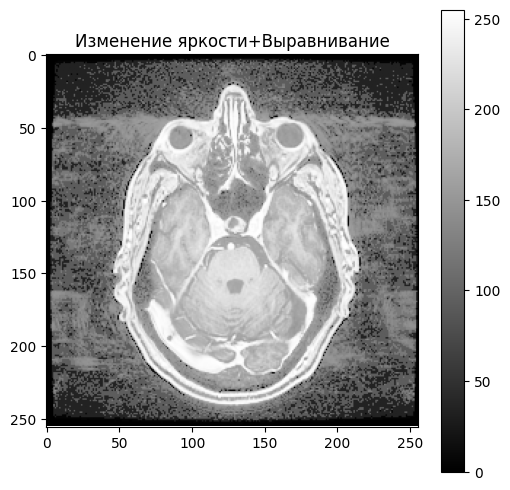

In [ ]:
plt.figure(figsize=(6, 6))
plt.imshow(equalized_image, cmap='gray')
plt.title('Изменение яркости+Выравнивание')
plt.colorbar()
plt.show()

In [ ]:
# Функция для коррекции гаммы (степенное преобразование)
def gamma_correction(equalized_image, gamma=1.0):
    # Нормализуем значения пикселей из [0, 255] в диапазон [0, 1]
    # Это необходимо для корректного возведения в степень
    normalized_image = equalized_image / np.max(equalized_image)

    # Применяем степенное преобразование (закон Gamma)
    # Если gamma > 1 — изображение темнеет, если gamma < 1 — светлеет
    gamma_image = np.power(normalized_image, gamma)

    # Возвращаем изображение в диапазон [0, 255] и приводим к типу uint8
    # Деление на np.max(gamma_image) гарантирует, что самый яркий пиксель станет 255
    transformed_image = np.uint8(255 * gamma_image / np.max(gamma_image))

    return transformed_image

# Пример использования: при gamma=3 изображение станет значительно контрастнее и темнее
gamma_image = gamma_correction(equalized_image, gamma=3)

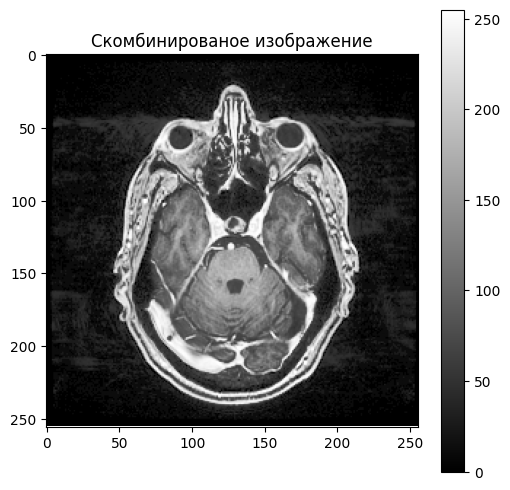

In [ ]:
# Отображаем изображение с поправленной гаммой
plt.figure(figsize=(6, 6))
plt.imshow(gamma_image, cmap='gray')
plt.title('Скомбинированое изображение')
plt.colorbar()
plt.show()

In [ ]:
# Проверяем, отличается ли тип данных изображения от стандартного 8-битного (uint8)
if gamma_image.dtype != np.uint8:
    image = cv2.normalize(gamma_image, None, 0, 255, cv2.NORM_MINMAX)
    image = image.astype(np.uint8)

In [ ]:
# Устанавливаем порог: пиксели с яркостью > 60 станут белыми (255)
# Пиксели с яркостью <= 60 станут черными (0)
thresh_value = 60
max_value = 255
threshold_value_used, binary_image = cv2.threshold(gamma_image, thresh_value, max_value, cv2.THRESH_BINARY)


In [ ]:
# Убедимся, что бинарное изображение имеет тип uint8
binary_image = binary_image.astype(np.uint8)

In [ ]:
# Поиск контуров на бинарном (черно-белом) изображении
contours, hierarchy = cv2.findContours(binary_image, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

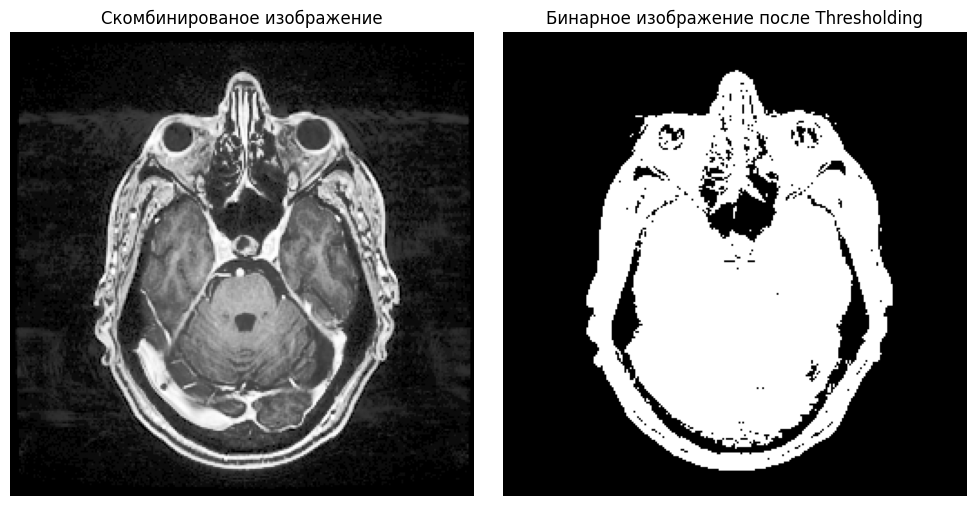

In [ ]:
# Отображение оригинального и бинарного изображений
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.title('Скомбинированое изображение')
plt.imshow(gamma_image, cmap='gray')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.title('Бинарное изображение после Thresholding')
plt.imshow(binary_image, cmap='gray')
plt.axis('off')

plt.tight_layout()
plt.show()

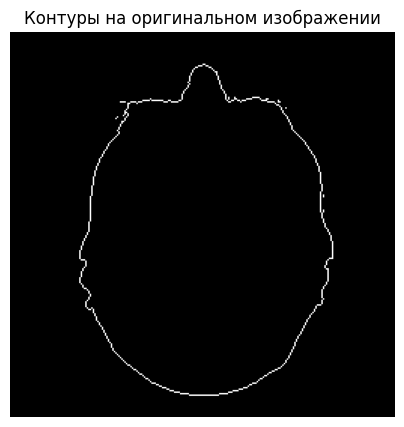

In [ ]:
# Создаем пустой черный холст (массив из нулей) такого же размера и типа,
# как и наше обработанное изображение (gamma_image)
contour_image = np.zeros_like(gamma_image)

# Рисуем найденные контуры на этом черном холсте
# 1. contour_image — целевое изображение (черный фон)
# 2. contours — список координат, найденных ранее функцией findContours
# 3. -1 — индекс контура. "-1" означает, что нужно нарисовать ВСЕ найденные контуры
# 4. 255 — цвет линии. В одноканальном (ч/б) изображении это будет белый цвет
# 5. thickness=1 — толщина линии контура в 1 пиксель
cv2.drawContours(contour_image, contours, -1, 255, thickness=1)

# В итоге contour_image — это черное изображение с тонкими белыми границами объектов

# Отображение изображения с контурами
plt.figure(figsize=(5, 5))
plt.title('Контуры на оригинальном изображении')
plt.imshow(contour_image, cmap='gray')
plt.axis('off')
plt.show()

In [ ]:
final_for_canny = gamma_image.astype(np.uint8)

# Применяем детектор границ Кэнни (Canny Edge Detector)
# 1. image — исходное 8-битное изображение (уже нормализованное)
# 2. threshold1=110 — нижний порог (L-порог).
#    Градиенты ниже этого значения игнорируются (не считаются границами).
# 3. threshold2=210 — верхний порог (H-порог).
#    Сильные градиенты выше этого значения точно считаются границами.
#    Пиксели между 110 и 210 принимаются только если они связаны с "сильными" границами.
edges = cv2.Canny(final_for_canny, threshold1=110, threshold2=210)

# Результат (edges) — это бинарная маска (0 или 255),
# где белым цветом выделены только тонкие линии контуров.

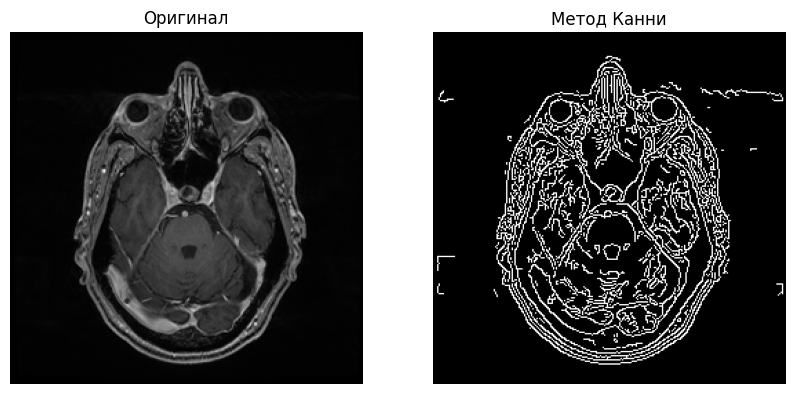

In [ ]:
# Отобразите оригинальное изображение и изображение с краями
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.title('Оригинал')
plt.imshow(image, cmap='gray')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.title('Метод Канни')
plt.imshow(edges, cmap='gray')
plt.axis('off')

plt.show()